In [3]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 


In [7]:

df = pd.read_csv(r"C:\Users\DELL\Downloads\PYTHON DATA ANALYTICS PROJECT\PYTHON DATA ANALYTICS PROJECT\PROJECT 1\HR_Analytics.csv")


In [9]:
df.head()

,EmpID,Age,AgeGroup,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,RM297,18,18-25,Yes,Travel_Rarely,230,Research & Development,3,3,Life Sciences,...,3,80,0,0,2,3,0,0,0,0.0
1,RM302,18,18-25,No,Travel_Rarely,812,Sales,10,3,Medical,...,1,80,0,0,2,3,0,0,0,0.0
2,RM458,18,18-25,Yes,Travel_Frequently,1306,Sales,5,3,Marketing,...,4,80,0,0,3,3,0,0,0,0.0
3,RM728,18,18-25,No,Non-Travel,287,Research & Development,5,2,Life Sciences,...,4,80,0,0,2,3,0,0,0,0.0
4,RM829,18,18-25,Yes,Non-Travel,247,Research & Development,8,1,Medical,...,4,80,0,0,0,3,0,0,0,0.0


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1480 entries, 0 to 1479
Data columns (total 38 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   EmpID                     1480 non-null   object 
 1   Age                       1480 non-null   int64  
 2   AgeGroup                  1480 non-null   object 
 3   Attrition                 1480 non-null   object 
 4   BusinessTravel            1480 non-null   object 
 5   DailyRate                 1480 non-null   int64  
 6   Department                1480 non-null   object 
 7   DistanceFromHome          1480 non-null   int64  
 8   Education                 1480 non-null   int64  
 9   EducationField            1480 non-null   object 
 10  EmployeeCount             1480 non-null   int64  
 11  EmployeeNumber            1480 non-null   int64  
 12  EnvironmentSatisfaction   1480 non-null   int64  
 13  Gender                    1480 non-null   object 
 14  HourlyRa

In [13]:
df.shape

(1480, 38)

In [15]:
df.isnull().sum()

EmpID                        0
Age                          0
AgeGroup                     0
Attrition                    0
BusinessTravel               0
DailyRate                    0
Department                   0
DistanceFromHome             0
Education                    0
EducationField               0
EmployeeCount                0
EmployeeNumber               0
EnvironmentSatisfaction      0
Gender                       0
HourlyRate                   0
JobInvolvement               0
JobLevel                     0
JobRole                      0
JobSatisfaction              0
MaritalStatus                0
MonthlyIncome                0
SalarySlab                   0
MonthlyRate                  0
NumCompaniesWorked           0
Over18                       0
OverTime                     0
PercentSalaryHike            0
PerformanceRating            0
RelationshipSatisfaction     0
StandardHours                0
StockOptionLevel             0
TotalWorkingYears            0
Training

In [17]:
df.duplicated().sum()

7

In [23]:
df.isnull().sum().sum()

57


### Question 1: Is the dataset clean and ready to analyze?

The HR dataset contains 1,480 rows and 38 colums.
There are 57 missing values in the YearsWithCurrManager co umn
and 7 duplicate recods.

Therefore, the dataset needs some cleaning before analysis.



In [29]:
### What is the overall monthly income distribution? 
df['MonthlyIncome'].describe()

count     1480.000000
mean      6504.985811
std       4700.261400
min       1009.000000
25%       2922.250000
50%       4933.000000
75%       8383.750000
max      19999.000000
Name: MonthlyIncome, dtype: float64

In [31]:
## Which department has the highest and lowest average monthly income?
df.groupby('Department')['MonthlyIncome'].mean()

Department
Human Resources           6654.507937
Research & Development    6280.365047
Sales                     6966.737778
Name: MonthlyIncome, dtype: float64

The Sales department has the highest average monthly income of approximately 6,967.
The Research and Development department has the lowest average monthly income of approximately 6,280.
Therefore, Sales has the highest average income among the three departments.

In [34]:
## . Does monthly income increase with job level? 
df.groupby('JobLevel')['MonthlyIncome'].mean()

JobLevel
1     2789.075229
2     5504.005566
3     9822.754545
4    15471.327103
5    19191.826087
Name: MonthlyIncome, dtype: float64



Yes, monthly income increases as job level increas .

Level 1 employees earn an average of approxim tely
2,789, while Level 5 employee  earn approxi ately
1,192.

This shows a strong positive relationshi  between
job level and monthly income.


In [37]:
## Is there a difference in average monthly income by gender? 

df.groupby('Gender')['MonthlyIncome'].mean()

Gender
Female    6684.404399
Male      6385.709786
Name: MonthlyIncome, dtype: float64

In [39]:
##  Do employees who leave the company have lower monthly income than those who stay?

df.groupby('Attrition')['MonthlyIncome'].mean()

Attrition
No     6829.294686
Yes    4812.584034
Name: MonthlyIncome, dtype: float64

In [43]:
## Calculate the attrition percentage 
df['Attrition'].value_counts(normalize=True)*100

Attrition
No     83.918919
Yes    16.081081
Name: proportion, dtype: float64



Yes, employees who leave the company have a lo er
average monthly incoe.

Employees who stayed earn approximately  ,829,
while employees who left earn approximately ,813.

The attrition rate is approximately16.08%.

This suggests that monthly income may be related
to employee attrition, but further analysis is
required to understand other reasons for leaving.


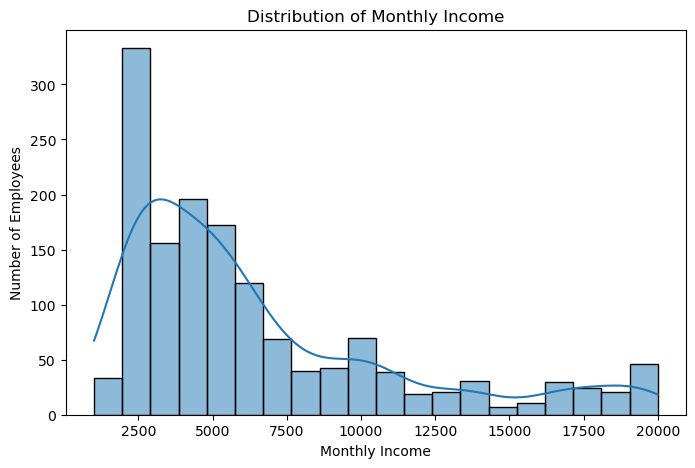

In [58]:
plt.figure(figsize=(8,5))

sns.histplot(df['MonthlyIncome'], bins=20, kde=True)

plt.title('Distribution of Monthly Income')
plt.xlabel('Monthly Income')
plt.ylabel('Number of Employees')

plt.show()


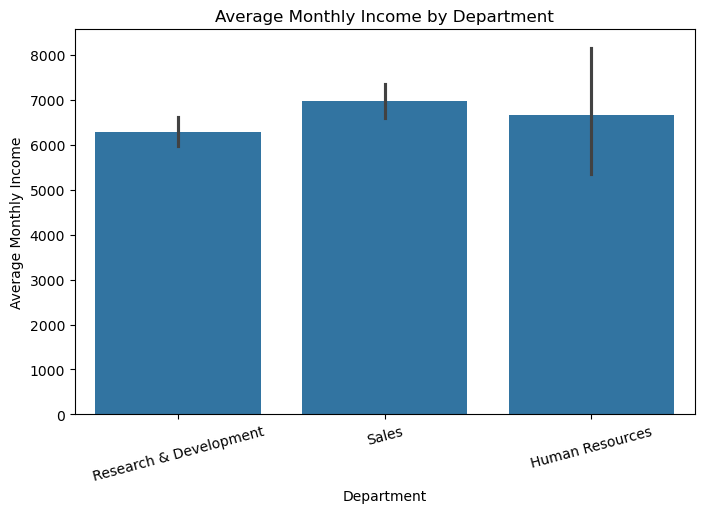

In [62]:
plt.figure(figsize=(8,5))

sns.barplot(x='Department',y='MonthlyIncome',data=df) 

plt.title('Average Monthly Income by Department')

plt.xlabel('Department')

plt.ylabel('Average Monthly Income')

plt.xticks(rotation=15)

plt.show()

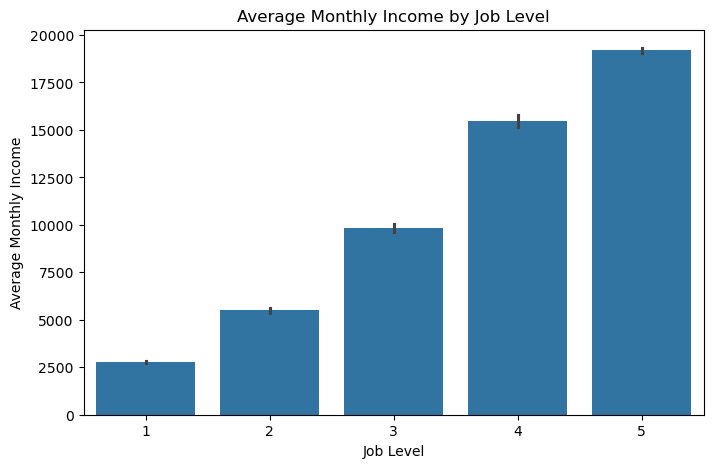

In [66]:

plt.figure(figsize=(8,5))

sns.barplot(x='JobLevel', y='MonthlyIncome', data=df)

plt.title('Average Monthly Income by Job Level')
plt.xlabel('Job Level')
plt.ylabel('Average Monthly Income')

plt.show()

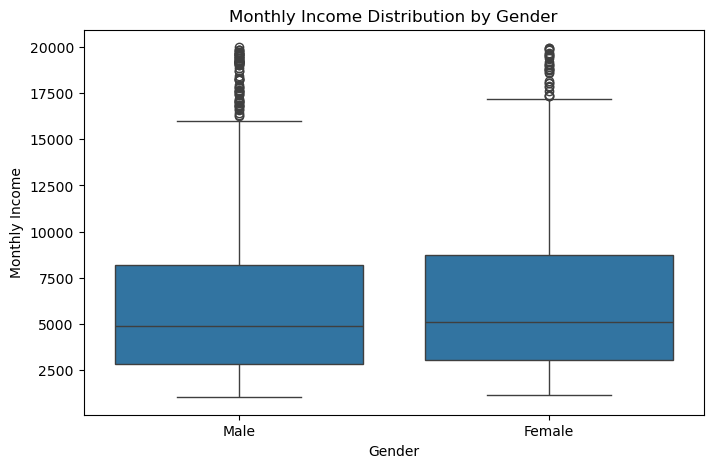

In [72]:

plt.figure(figsize=(8,5))

sns.boxplot(x='Gender', y='MonthlyIncome', data=df)

plt.title('Monthly Income Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Monthly Income')

plt.show()

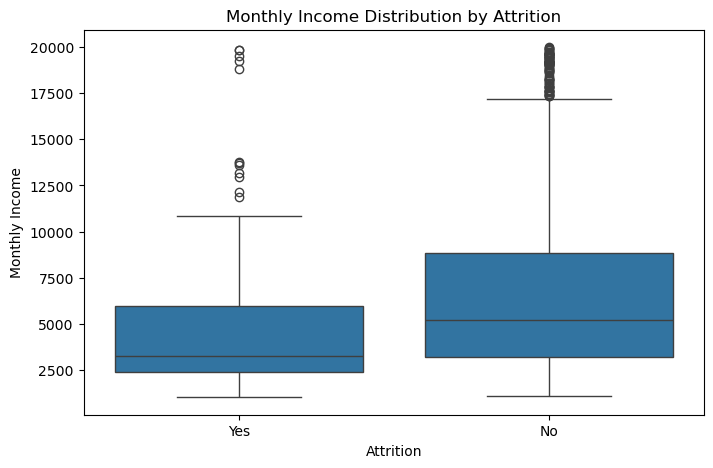

In [74]:
plt.figure(figsize=(8,5))

sns.boxplot(x='Attrition',y='MonthlyIncome',data=df)

plt.title('Monthly Income Distribution by Attrition')

plt.xlabel('Attrition')
plt.ylabel('Monthly Income')
plt.show()

## HR Analyis Project ConclusionN

In this project, I analyzed employee monthly incme
using Python, Pandas, NumPy, Matplotlib and Seabon.

I explored salary distribution, departmen -wise
income, job levels, gender differences and e ployee
attition.

The analysis sho and
business insights.
